In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/digit-recognizer/sample_submission.csv
/kaggle/input/competitions/digit-recognizer/train.csv
/kaggle/input/competitions/digit-recognizer/test.csv


In [2]:
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

# filter warnings
warnings.filterwarnings('ignore')

In [3]:
train = pd.read_csv("/kaggle/input/competitions/digit-recognizer/train.csv")
train.shape

(42000, 785)

In [4]:
train.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
test = pd.read_csv("/kaggle/input/competitions/digit-recognizer/test.csv")
test.shape

(28000, 784)

In [6]:
test.head()

,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [7]:
Y_train = train["label"]
X_train = train.drop(labels = ["label"],axis =1)

In [8]:
Y_train.value_counts()

label
1    4684
7    4401
3    4351
9    4188
2    4177
6    4137
0    4132
4    4072
8    4063
5    3795
Name: count, dtype: int64

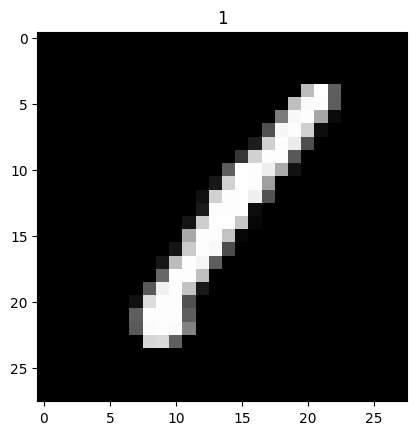

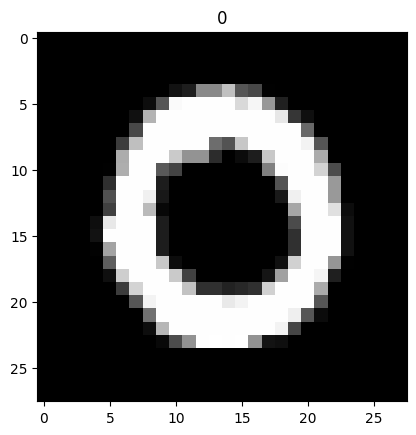

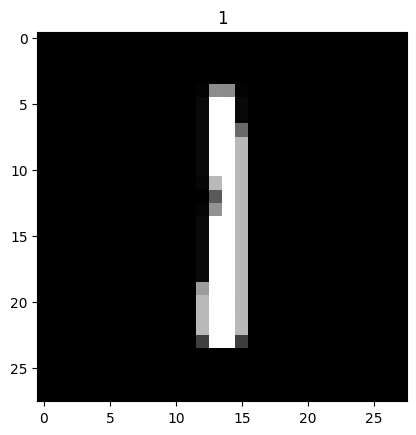

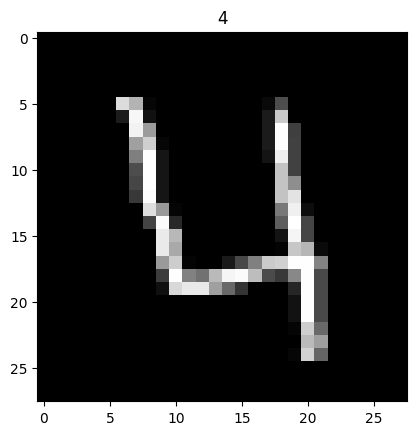

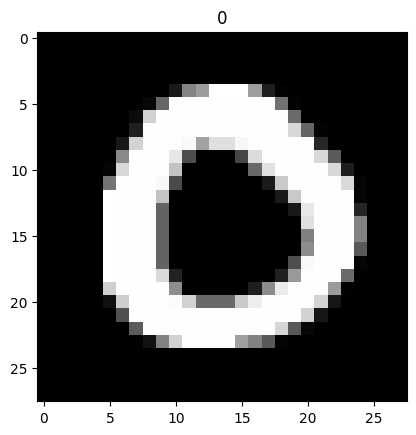

In [9]:
# plot some samples
for i in range(5):
    img = X_train.iloc[i].to_numpy()
    img = img.reshape((28,28))
    plt.imshow(img,cmap='gray')
    plt.title(train.iloc[i,0])
    plt.show()

In [10]:
X_train = X_train / 255.0
test = test / 255.0
print("x_train shape: ",X_train.shape)
print("test shape: ",test.shape)

x_train shape:  (42000, 784)
test shape:  (28000, 784)


In [11]:
# Reshape
X_train = X_train.values.reshape(-1,28,28,1)
test = test.values.reshape(-1,28,28,1)
print("X_train shape: ",X_train.shape)
print("test shape: ",test.shape)

X_train shape:  (42000, 28, 28, 1)
test shape:  (28000, 28, 28, 1)


In [12]:
from keras.utils import to_categorical # convert to one-hot-encoding
print("before encoding")
Y_train.shape
Y_train = to_categorical(Y_train, num_classes = 10)
print("after encoding")
Y_train.shape

before encoding
after encoding


(42000, 10)

In [13]:
Y_train[0]

array([0., 1., 0., 0., 0., 0., 0., 0., 0., 0.])

In [14]:
from sklearn.model_selection import train_test_split #train test split
X_train, X_val, Y_train, Y_val = train_test_split(X_train, Y_train, test_size = 0.2, random_state=42)

In [15]:
from sklearn.metrics import confusion_matrix
import itertools
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPool2D
from keras.optimizers import RMSprop,Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.callbacks import ReduceLROnPlateau

model = Sequential()
# cnn
model.add(Conv2D(filters = 8, kernel_size = (5,5),padding = 'Same', 
                 activation ='relu', input_shape = (28,28,1)))
model.add(MaxPool2D(pool_size=(2,2)))
model.add(Dropout(0.25))
model.add(Conv2D(filters = 16, kernel_size = (3,3),padding = 'Same', 
                 activation ='relu'))
model.add(MaxPool2D(pool_size=(2,2), strides=(2,2)))
model.add(Dropout(0.25))
# fully connected
model.add(Flatten())
model.add(Dense(256, activation = "relu"))
model.add(Dropout(0.5))
model.add(Dense(10, activation = "softmax"))

I0000 00:00:1790361435.024194      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790361435.026857      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [22]:
# Define the optimizer and run model
optimizer = Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999)
model.compile(optimizer = optimizer , loss = "categorical_crossentropy", metrics=["accuracy"])

In [25]:
history = model.fit(
    X_train,
    Y_train,
    batch_size=250,
    epochs=10,
    validation_data=(X_val, Y_val)
)

Epoch 1/10
 34/135 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3186 - loss: 1.9730

I0000 00:00:1790361980.892053     133 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


135/135 ━━━━━━━━━━━━━━━━━━━━ 11s 37ms/step - accuracy: 0.7486 - loss: 0.7751 - val_accuracy: 0.9330 - val_loss: 0.2291
Epoch 2/10
135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9130 - loss: 0.2837 - val_accuracy: 0.9571 - val_loss: 0.1462
Epoch 3/10
135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9354 - loss: 0.2088 - val_accuracy: 0.9676 - val_loss: 0.1159
Epoch 4/10
135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9431 - loss: 0.1768 - val_accuracy: 0.9723 - val_loss: 0.0944
Epoch 5/10
135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9521 - loss: 0.1507 - val_accuracy: 0.9770 - val_loss: 0.0786
Epoch 6/10
135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9575 - loss: 0.1359 - val_accuracy: 0.9775 - val_loss: 0.0738
Epoch 7/10
135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9624 - loss: 0.1218 - val_accuracy: 0.9812 - val_loss: 0.0660
Epoch 8/10
135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9630 - loss: 0.1160 - val_accuracy: 0.9817 - va

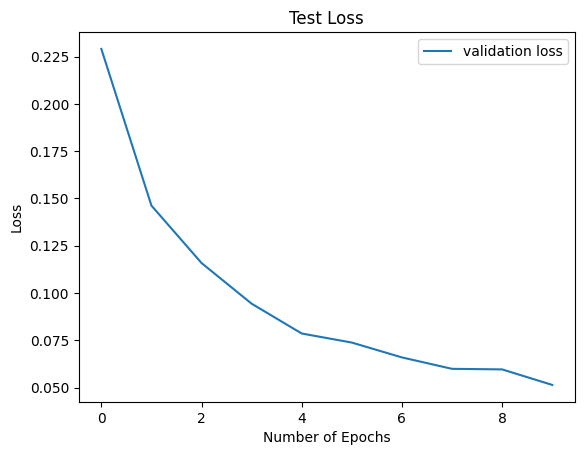

In [27]:
plt.plot(history.history['val_loss'], label="validation loss")
plt.title("Test Loss")
plt.xlabel("Number of Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

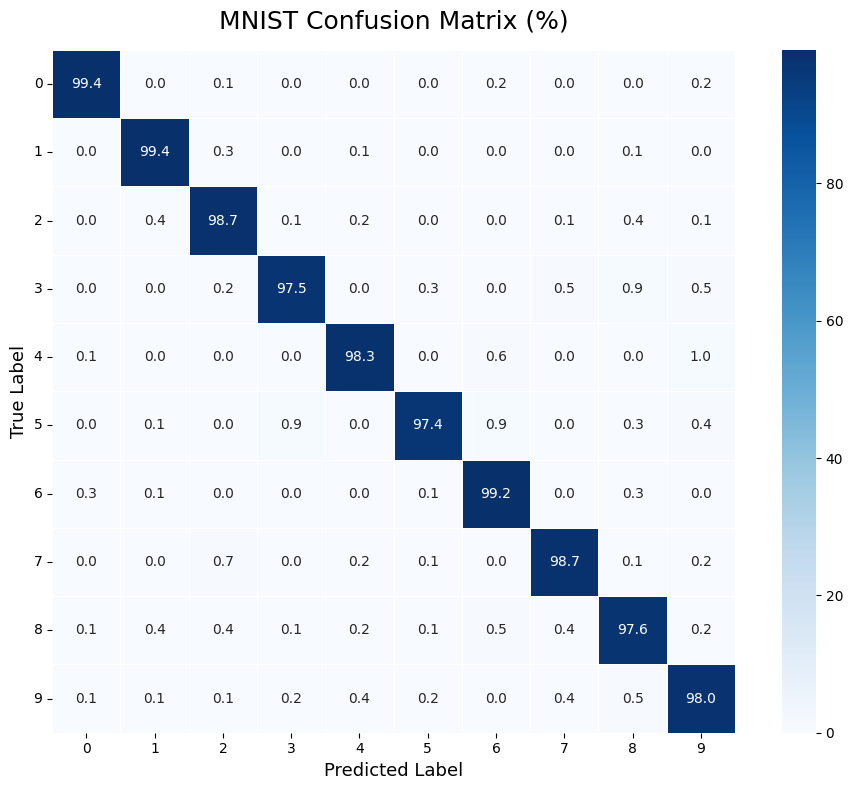

In [29]:
confusion_pct = (
    confusion_mtx /
    confusion_mtx.sum(axis=1, keepdims=True)
) * 100

plt.figure(figsize=(10, 8))

sns.heatmap(
    confusion_pct,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    linewidths=0.5,
    square=True,
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.title("MNIST Confusion Matrix (%)", fontsize=18, pad=15)
plt.xlabel("Predicted Label", fontsize=13)
plt.ylabel("True Label", fontsize=13)

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [30]:
test_predictions = model.predict(test, verbose=0)

# probabilities -> digit
test_predictions = np.argmax(
    test_predictions,
    axis=1
)

print(test_predictions[:20])

[2 0 9 9 3 7 0 3 0 3 5 7 4 0 4 3 3 1 9 0]


In [31]:
submission = pd.DataFrame({
    "ImageId": np.arange(1, len(test_predictions) + 1),
    "Label": test_predictions
})

print(submission.head())

submission.to_csv(
    "submission.csv",
    index=False
)

print("submission.csv created!")

   ImageId  Label
0        1      2
1        2      0
2        3      9
3        4      9
4        5      3
submission.csv created!
